In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv("IMDB Dataset.csv")

# Display first 5 rows
print(df.head())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [3]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("Columns:", df.columns)

# Check dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print("Duplicates:", df.duplicated().sum())

Dataset Shape: (50000, 2)
Columns: Index(['review', 'sentiment'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None
review       0
sentiment    0
dtype: int64
Duplicates: 418


In [4]:
print(df['sentiment'].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


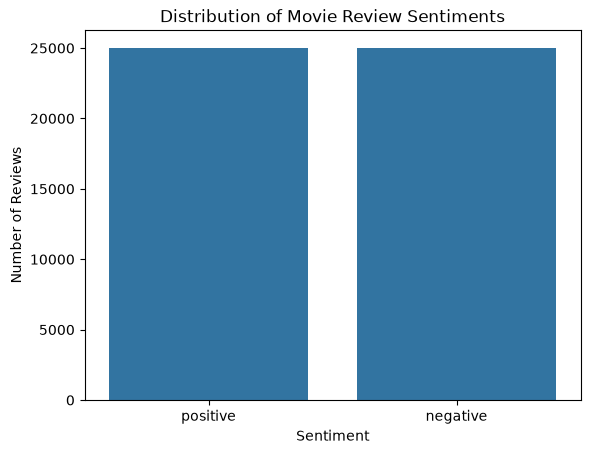

In [5]:
#This tells us how many positive and negative reviews are in our dataset.Visualize the distribution:
sns.countplot(data=df, x='sentiment')

plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [6]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\REAL\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\REAL\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\REAL\AppData\Roaming\nltk_data...


True

In [7]:
# Initialize NLP tools
stop_words = set(stopwords.words('english'))

stemmer = PorterStemmer()

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenization
    words = text.split()

    # Remove stop words
    words = [word for word in words if word not in stop_words]

    # Lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    # Join words
    return ' '.join(words)

In [8]:
df['cleaned_review'] = df['review'].apply(clean_text)

print(df[['review', 'cleaned_review']].head())

                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   
3  Basically there's a family where a little boy ...   
4  Petter Mattei's "Love in the Time of Money" is...   

                                      cleaned_review  
0  one reviewer mentioned watching oz episode you...  
1  wonderful little production filming technique ...  
2  thought wonderful way spend time hot summer we...  
3  basically there family little boy jake think t...  
4  petter matteis love time money visually stunni...  


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [10]:
# Separate input features and target labels
X = df['cleaned_review']
y = df['sentiment']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Initialize TF-IDF
tfidf = TfidfVectorizer(max_features=5000)

# Convert text into numerical features
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

# Display results
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (40000, 5000)
Testing shape: (10000, 5000)


In [11]:
# Display first review
print("Original Review:")
print(X_train.iloc[0])

# Display TF-IDF values
print("\nTF-IDF Representation:")
print(X_train_tfidf[0].toarray())

Original Review:
caught little gem totally accident back revival theatre see two old silly scifi movie theatre packed full warning showed bunch scifi short spoof get u mood somewhat amusing came within second audience hysteric biggest laugh came showed princess laia huge cinnamon bun instead hair head look camera give grim smile nod made even funnier gotta see chewabacca played look like muppet extremely silly stupidbut couldnt stop laughing dialogue drowned laughter also know star war pretty well even funnierthey deliberately poke fun dialogue really work audience definite

TF-IDF Representation:
[[0. 0. 0. ... 0. 0. 0.]]


In [12]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [13]:
# Predict sentiment on test data
y_pred = model.predict(X_test_tfidf)

# Display first 10 predictions
print("Predictions:", y_pred[:10])

# Display actual labels
print("Actual:", y_test.iloc[:10].values)

Predictions: ['negative' 'positive' 'positive' 'negative' 'negative' 'negative'
 'negative' 'negative' 'negative' 'negative']
Actual: <StringArray>
['negative', 'negative', 'positive', 'negative', 'negative', 'negative',
 'negative', 'negative', 'negative', 'negative']
Length: 10, dtype: str


In [14]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

# Detailed evaluation
print(classification_report(y_test, y_pred))

# Confusion matrix
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 0.8859
              precision    recall  f1-score   support

    negative       0.89      0.87      0.88      5000
    positive       0.88      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000

[[4373  627]
 [ 514 4486]]


In [15]:
sample_review = [
    "This movie was absolutely amazing and wonderful"
]

# Transform the review using trained TF-IDF
sample_vector = tfidf.transform(sample_review)

# Predict sentiment
prediction = model.predict(sample_vector)

print("Movie Review Sentiment:", prediction[0])

Movie Review Sentiment: positive


In [16]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [17]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC()
}

results = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_tfidf, y_train)

    # Make predictions
    predictions = model.predict(X_test_tfidf)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print(name, "Accuracy:", accuracy)

Logistic Regression Accuracy: 0.8859
Naive Bayes Accuracy: 0.8529
SVM Accuracy: 0.8775


In [18]:
for model, accuracy in results.items():
    print(f"{model}: {accuracy * 100:.2f}%")

Logistic Regression: 88.59%
Naive Bayes: 85.29%
SVM: 87.75%


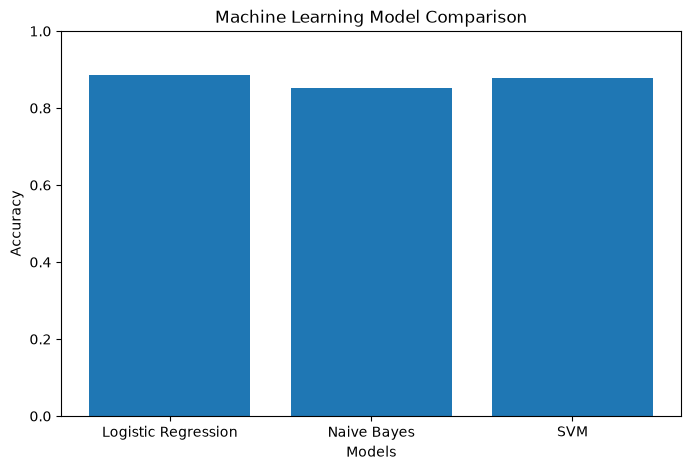

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.title("Machine Learning Model Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.show()

In [20]:
import joblib

In [21]:
best_model_name = max(results, key=results.get)

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Logistic Regression


In [22]:
joblib.dump(best_model, "sentiment_model.pkl")

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
